# Práctica 1 · Parte 2: ataque adversario FGSM a una CNN y a una SVM (MNIST)

**Grupo:** Laura Somolinos, Alejandro Blanco, Adriana González, Lucas Tianming Miguel · Investigación Operativa, curso 26‑27.

Ejecución y explicacion de todos los apartados de la parte 2

| Apartado del enunciado | Secciones del notebook |
|---|---|
| 1. CNN ≥ 95 % y nº de parámetros | `entrenar_cnn.py` (entrenamiento) · sección 2  (parámetros) |
| 2. SVM con núcleo gaussiano | `entrenar_svm.py` (entrenamiento) · sección 2 (configuración) |
| 3. Función FGSM propia | `fgsm.py` (`ataque_fgsm`) · sección 2 (comprobaciones) |
| 4. Imágenes adversarias, predicción con CNN y SVM, visualización | secciones 3 a 5 |
| 5. Adversarias de todo train/test y error de cada modelo | sección 6 |
| 6. Entrenamiento adversario y error en el test conjunto de 20.000 | sección 7 |
| 7. Imágenes doblemente adversarias | sección 8 |

Conclusiones en la sección 10 y se calculan a partir de las tablas del cuaderno. Las funciones auxiliares de los apartados opcionales están en `adversarial.py`.

En las secciones 3–5 los ataques se generan **contra la CNN**, con las etiquetas verdaderas. Al pasarlos por la SVM medimos transferencia del ataque, no un FGSM optimizado contra la SVM. No se utiliza ninguna librería de ataques adversarios.

## 0. Configuración

- Modo rápido: 1000 imágenes, solo para comprobar que todo funciona (afecta a las secciones 3–5).
- Modo completo: 10.000 imágenes de test para las tablas y gráficas definitivas.
- Las secciones 6–9 usan siempre el test completo, sea cual sea el modo.
- Las secciones 1–6 solo cargan la CNN y la SVM guardadas (cnn_mnist.pth, svm_rbf_mnist.joblib) no se reentrenan. En la sección 7 se entrenan los modelos adversarios, que se guardan en resultados/ y se reutilizan si ya existen.
- Los píxeles están normalizados a [0,1]; epsilon está en esa escala (0,15 ≈ 38 niveles sobre 255) más o menos aunque se puede probar otro valor cercano como 0.2.
- Semilla fija (SEMILLA = 42).

In [10]:
from pathlib import Path
import random
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from IPython.display import display

from entrenar_cnn import CNNMNIST
from fgsm import ataque_fgsm

SEMILLA = 42
MODO = "completo" # "rapido" = 1000 imágenes | "completo" = 10000
LOTE = 128
EPSILONS = [0.0, 0.025, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

CARPETA = Path.cwd().resolve()
CARPETA_SALIDAS = CARPETA / "resultados"
CARPETA_SALIDAS.mkdir(parents=True, exist_ok=True)

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

dispositivo = torch.device("cpu")
print(f"Carpeta: {CARPETA}")
print(f"Modo: {MODO}; dispositivo: {dispositivo}")
import sklearn, torchvision


Carpeta: \\wsl.localhost\Ubuntu-24.04\home\laura\proyectos\practica1_parte2
Modo: completo; dispositivo: cpu


## 1. Cargar los modelos y el test de MNIST

La CNN y la SVM reciben exactamente los mismos ejemplos de test. La CNN usa tensores de forma (lote,1,28,28) y la SVM recibe esos píxeles aplanados (lote,784).

In [11]:
ruta_cnn = CARPETA / "cnn_mnist.pth"
ruta_svm = CARPETA / "svm_rbf_mnist.joblib"
for ruta in [ruta_cnn, ruta_svm]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta {ruta}. Coloca este notebook junto a los modelos guardados.")

cnn = CNNMNIST().to(dispositivo)
cnn.load_state_dict(torch.load(ruta_cnn, map_location=dispositivo, weights_only=True))
cnn.eval()

svm = joblib.load(ruta_svm)

mnist_test = datasets.MNIST(root=CARPETA / "datos", train=False, download=True, transform=transforms.ToTensor())

if MODO == "rapido":
    indices = np.random.default_rng(SEMILLA).choice(len(mnist_test), 1000, replace=False)
    indices = np.sort(indices).tolist()
elif MODO == "completo":
    indices = list(range(len(mnist_test)))

subconjunto = Subset(mnist_test, indices)
cargador = DataLoader(subconjunto, batch_size=LOTE, shuffle=False, num_workers=0)
N = len(subconjunto)
print(f"Test disponible: {len(mnist_test)} | imágenes evaluadas: {N}")
print(f"Total de parámetros CNN: {sum(p.numel() for p in cnn.parameters()):,}")
print(f"Vectores de soporte SVM: {len(svm.support_):,}")


Test disponible: 10000 | imágenes evaluadas: 10000
Total de parámetros CNN: 105,866
Vectores de soporte SVM: 11,697


C:\Users\laura\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:440: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.9.1 when using version 1.7.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 2. Apartados 1–3: red, SVM y función FGSM

**Apartado 1.** La CNN tiene dos bloques convolución → ReLU → max‑pooling y dos capas lineales (arquitectura propia, distinta de la vista en clase). Contamos sus parámetros capa a capa.

**Apartado 2.** SVM con núcleo gaussiano (RBF), C=10, gamma="scale", entrenada con 60.000 imágenes de train.

**Apartado 3.** ataque_fgsm (en fgsm.py) calcula el gradiente de la pérdida respecto a los píxeles con torch.autograd.grad y construye x_adv = clip(x + ε·signo(gradiente), 0, 1). Antes de usarla comprobamos que cumple lo que promete: 
- (i) ningún píxel cambia más de epsilon
- (ii) los píxeles siguen en [0,1]
- (iii) con epsilon=0 no cambia nada
- (iv) la pérdida de la CNN aumenta
- (v) el signo de la perturbación coincide con el del gradiente.

In [13]:
# Apartado 1: arquitectura y número de parámetros (capa a capa)
print(cnn)
desglose = [(nombre, p.numel()) for nombre, p in cnn.named_parameters()]
for nombre, n in desglose:
    print(f"{nombre:<32}{n:>9,}")
print(f"{'TOTAL de parámetros':<32}{sum(n for _, n in desglose):>9,}")

# Apartado 2: configuración de la SVM (gamma="scale" = 1 / (784 · varianza de los datos de entrenamiento))
print(f"\nSVM: kernel={svm.kernel} | C={svm.C} | gamma={svm._gamma:.6f} | clases={len(svm.classes_)} | "
      f"vectores de soporte={len(svm.support_):,} (de 12.000 imágenes de entrenamiento)")

CNNMNIST(
  (caracteristicas): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (clasificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
caracteristicas.0.weight              144
caracteristicas.0.bias                 16
caracteristicas.3.weight            4,608
caracteristicas.3.bias                 32
clasificador.1.weight             100,352
clasificador.1.bias                    64
clasificador.3.weight                 640
clasificador.3.bias                    10
TOTAL de parámetros               105,866

SVM: kern

In [14]:
# Apartado 3: comprobaciones de la función ataque_fgsm con 1000 imágenes de test
x_t, y_t = next(iter(DataLoader(subconjunto, batch_size=1000, shuffle=False, num_workers=0)))

def perdida_media(x):
    with torch.no_grad():
        return torch.nn.functional.cross_entropy(cnn(x), y_t).item()

# gradiente a mano para comparar el signo con la perturbación aplicada
x_g = x_t.clone().requires_grad_(True)
grad = torch.autograd.grad(torch.nn.functional.cross_entropy(cnn(x_g), y_t), x_g)[0]

filas = []
for eps in [0.0, 0.05, 0.15]:
    x_a = ataque_fgsm(cnn, x_t, y_t, eps)
    delta = x_a - x_t
    sin_recorte = (grad != 0) & (x_t + eps * grad.sign() >= 0) & (x_t + eps * grad.sign() <= 1)   # píxeles que el clamp no toca
    filas.append({
        "epsilon": eps,
        "max |x_adv - x|": delta.abs().max().item(),
        "mín / máx píxel": f"{x_a.min().item():.2f} / {x_a.max().item():.2f}",
        "pérdida original": perdida_media(x_t),
        "pérdida adversaria": perdida_media(x_a),
        "signo = signo del gradiente (%)": 100 * (delta[sin_recorte].sign() == grad[sin_recorte].sign()).float().mean().item() if eps > 0 else float("nan"),
        "píxeles con gradiente 0 (%)": 100 * (grad == 0).float().mean().item(),
    })
    assert delta.abs().max().item() <= eps + 1e-6 and x_a.min() >= 0 and x_a.max() <= 1
assert torch.equal(ataque_fgsm(cnn, x_t, y_t, 0.0), x_t)        # con epsilon = 0 la imagen no cambia
display(pd.DataFrame(filas).round(4))
print("Comprobaciones superadas: cota L-inf, rango [0,1], epsilon=0 y aumento de la pérdida.")

,epsilon,max |x_adv - x|,mín / máx píxel,pérdida original,pérdida adversaria,signo = signo del gradiente (%),píxeles con gradiente 0 (%)
0,0.00,0.00,0.00 / 1.00,0.0449,0.0449,NaN,0.0
1,0.05,0.05,0.00 / 1.00,0.0449,0.2014,100.0,0.0
2,0.15,0.15,0.00 / 1.00,0.0449,1.7353,100.0,0.0


Comprobaciones superadas: cota L-inf, rango [0,1], epsilon=0 y aumento de la pérdida.


## 3. Prueba con varios epsilons: CNN y transferencia a SVM

Para cada imagen:

1. Generamos FGSM usando la CNN y la etiqueta real.
2. Clasificamos tanto la original como la adversaria con ambos modelos.
3. Registramos la precisión adversaria y la proporción de ataques exitosos entre las imágenes que la CNN clasificaba correctamente antes del ataque.

La tasa de éxito FGSM es una medida condicionada a aciertos iniciales, no el porcentaje de cambios sobre cualquier imagen. También medimos el cambio de predicción en SVM para estudiar transferencia.

In [15]:
def evaluar_epsilon(epsilon, cargador, cnn, svm):
    """Evalúa el FGSM generado contra la CNN y su transferencia a la SVM."""
    totales = {k: 0 for k in [
        "n", "cnn_original", "cnn_adv", "svm_original", "svm_adv",
        "cnn_correctas_iniciales", "cnn_enganyadas",
        "svm_correctas_iniciales", "svm_enganyadas", "cambios_cnn", "cambios_svm"
    ]}
    perturbacion_maxima = 0.0
    inicio = time.perf_counter()

    for x, y in cargador:
        x, y = x.to(dispositivo), y.to(dispositivo)
        # El ataque requiere gradientes
        x_adv = ataque_fgsm(cnn, x, y, epsilon)

        #verificar que la perturbación cumple la cota L-infinito y que los píxeles son válidos.
        diferencia = (x_adv - x).abs().max().item()
        perturbacion_maxima = max(perturbacion_maxima, diferencia)
        assert diferencia <= epsilon + 1e-6
        assert x_adv.min().item() >= 0 and x_adv.max().item() <= 1

        with torch.no_grad():
            pred_cnn = cnn(x).argmax(dim=1).cpu().numpy()
            pred_cnn_adv = cnn(x_adv).argmax(dim=1).cpu().numpy()

        # SVC opera sobre un vector de 784 píxeles. Los mismos píxeles, sin normalización extra.
        pred_svm = svm.predict(x.cpu().numpy().reshape(len(x), 784))
        pred_svm_adv = svm.predict(x_adv.cpu().numpy().reshape(len(x), 784))
        reales = y.cpu().numpy()

        bien_cnn = pred_cnn == reales
        bien_svm = pred_svm == reales
        totales["n"] += len(reales)
        totales["cnn_original"] += int(bien_cnn.sum())
        totales["cnn_adv"] += int((pred_cnn_adv == reales).sum())
        totales["svm_original"] += int(bien_svm.sum())
        totales["svm_adv"] += int((pred_svm_adv == reales).sum())
        totales["cnn_correctas_iniciales"] += int(bien_cnn.sum())
        totales["cnn_enganyadas"] += int((bien_cnn & (pred_cnn_adv != reales)).sum())
        totales["svm_correctas_iniciales"] += int(bien_svm.sum())
        totales["svm_enganyadas"] += int((bien_svm & (pred_svm_adv != reales)).sum())
        totales["cambios_cnn"] += int((pred_cnn_adv != pred_cnn).sum())
        totales["cambios_svm"] += int((pred_svm_adv != pred_svm).sum())

    n = totales["n"]
    return {
        "epsilon": epsilon,
        "n": n,
        "cnn_original_pct": 100 * totales["cnn_original"] / n,
        "cnn_adv_pct": 100 * totales["cnn_adv"] / n,
        "svm_original_pct": 100 * totales["svm_original"] / n,
        "svm_adv_pct": 100 * totales["svm_adv"] / n,
        "exito_fgsm_cnn_pct": 100 * totales["cnn_enganyadas"] / max(1, totales["cnn_correctas_iniciales"]),
        "transferencia_svm_pct": 100 * totales["svm_enganyadas"] / max(1, totales["svm_correctas_iniciales"]),
        "cambios_cnn_pct": 100 * totales["cambios_cnn"] / n,
        "cambios_svm_pct": 100 * totales["cambios_svm"] / n,
        "perturbacion_maxima": perturbacion_maxima,
        "segundos": round(time.perf_counter() - inicio, 2),
    }

filas = []
for epsilon in EPSILONS:
    resultado = evaluar_epsilon(epsilon, cargador, cnn, svm)
    filas.append(resultado)
    #progreso tras cada epsilon, si se interrumpe, conservamos lo completado.
    pd.DataFrame(filas).to_csv(CARPETA_SALIDAS / f"metricas_{MODO}.csv", index=False)
    print(f"epsilon={epsilon:.3f} | CNN={resultado['cnn_adv_pct']:.2f}% | "
          f"SVM={resultado['svm_adv_pct']:.2f}% | {resultado['segundos']} s")

resultados = pd.DataFrame(filas)
display(resultados.round(2))


epsilon=0.000 | CNN=98.61% | SVM=98.37% | 164.79 s
epsilon=0.025 | CNN=97.24% | SVM=97.82% | 169.98 s
epsilon=0.050 | CNN=94.50% | SVM=96.82% | 160.62 s
epsilon=0.100 | CNN=80.34% | SVM=91.79% | 164.98 s
epsilon=0.150 | CNN=52.96% | SVM=73.20% | 162.68 s
epsilon=0.200 | CNN=23.91% | SVM=52.57% | 171.43 s
epsilon=0.250 | CNN=8.24% | SVM=36.94% | 165.48 s
epsilon=0.300 | CNN=2.97% | SVM=24.48% | 165.14 s


,epsilon,n,cnn_original_pct,cnn_adv_pct,svm_original_pct,svm_adv_pct,exito_fgsm_cnn_pct,transferencia_svm_pct,cambios_cnn_pct,cambios_svm_pct,perturbacion_maxima,segundos
0,0.00,10000,98.61,98.61,98.37,98.37,0.00,0.00,0.00,0.00,0.00,164.79
1,0.02,10000,98.61,97.24,98.37,97.82,1.39,0.56,1.38,0.61,0.03,169.98
2,0.05,10000,98.61,94.50,98.37,96.82,4.17,1.59,4.12,1.69,0.05,160.62
3,0.10,10000,98.61,80.34,98.37,91.79,18.53,6.70,18.31,6.83,0.10,164.98
4,0.15,10000,98.61,52.96,98.37,73.20,46.29,25.59,45.73,25.46,0.15,162.68
5,0.20,10000,98.61,23.91,98.37,52.57,75.75,46.56,74.81,46.16,0.20,171.43
6,0.25,10000,98.61,8.24,98.37,36.94,91.64,62.45,90.48,61.88,0.25,165.48
7,0.30,10000,98.61,2.97,98.37,24.48,96.99,75.11,95.78,74.43,0.30,165.14


## 4. Comparación gráfica de precisión

En epsilon=0 no hay ataque y la precisión debe coincidir con la obtenida al evaluar los modelos sobre **el mismo subconjunto**. Con MODO="completo" debemos recuperar exactamente la precisión que imprimen los scripts de entrenamiento (98,61 % la CNN y 98,37 % la SVM con los modelos entregados).

GRÁFICAS: La primera muestra la precisión de cada modelo al crecer epsilon (la CNN, atacada directamente, cae más rápido que la SVM, que recibe un ataque calculado para otro modelo) Esto se debe a que es una trasferencia de ataque no es un ataque específico para la SVM por ese motivo se ve que no cae tan rápido no porque esta sea más robusta. La segunda muestra qué fracción de las imágenes que cada modelo acertaba pasa a fallar.

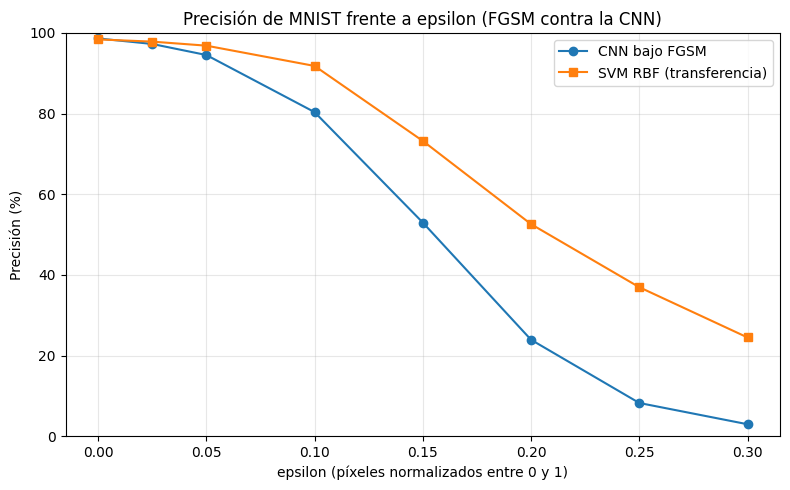

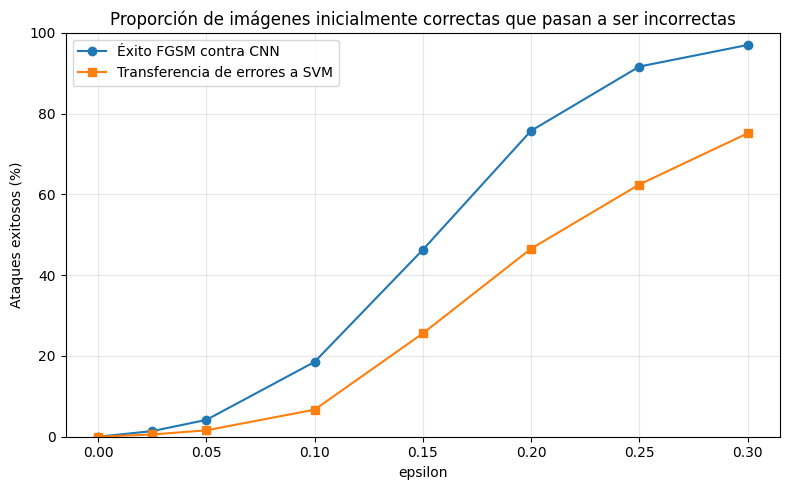

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resultados["epsilon"], resultados["cnn_adv_pct"], marker="o", label="CNN bajo FGSM")
ax.plot(resultados["epsilon"], resultados["svm_adv_pct"], marker="s", label="SVM RBF (transferencia)")
ax.set(title="Precisión de MNIST frente a epsilon (FGSM contra la CNN)",
       xlabel="epsilon (píxeles normalizados entre 0 y 1)", ylabel="Precisión (%)")
ax.set_ylim(0, 100)
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_SALIDAS / f"precision_vs_epsilon_{MODO}.png", dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resultados["epsilon"], resultados["exito_fgsm_cnn_pct"], marker="o", label="Éxito FGSM contra CNN")
ax.plot(resultados["epsilon"], resultados["transferencia_svm_pct"], marker="s", label="Transferencia de errores a SVM")
ax.set(title="Proporción de imágenes inicialmente correctas que pasan a ser incorrectas",
       xlabel="epsilon", ylabel="Ataques exitosos (%)")
ax.set_ylim(0, 100)
ax.grid(alpha=.3)
ax.legend()
fig.tight_layout()
fig.savefig(CARPETA_SALIDAS / f"exito_vs_epsilon_{MODO}.png", dpi=180)
plt.show()


## 5. Elegir epsilon y visualizar originales y adversarias

No hay un epsilon que sea el perfecto. Se elige un valor observando la tabla y las gráficas: uno que aporte cambios de clasificación con perturbaciones que no destruyan la identidad visual del dígito, es decir que lo podamos identificar.

Se seleccionan varios ejemplos que la CNN clasificaba bien originalmente; damos prioridad a aquellos en los que el ataque sí la engaña. Mostramos predicción original/adversaria de ambos modelos y la etiqueta verdadera.

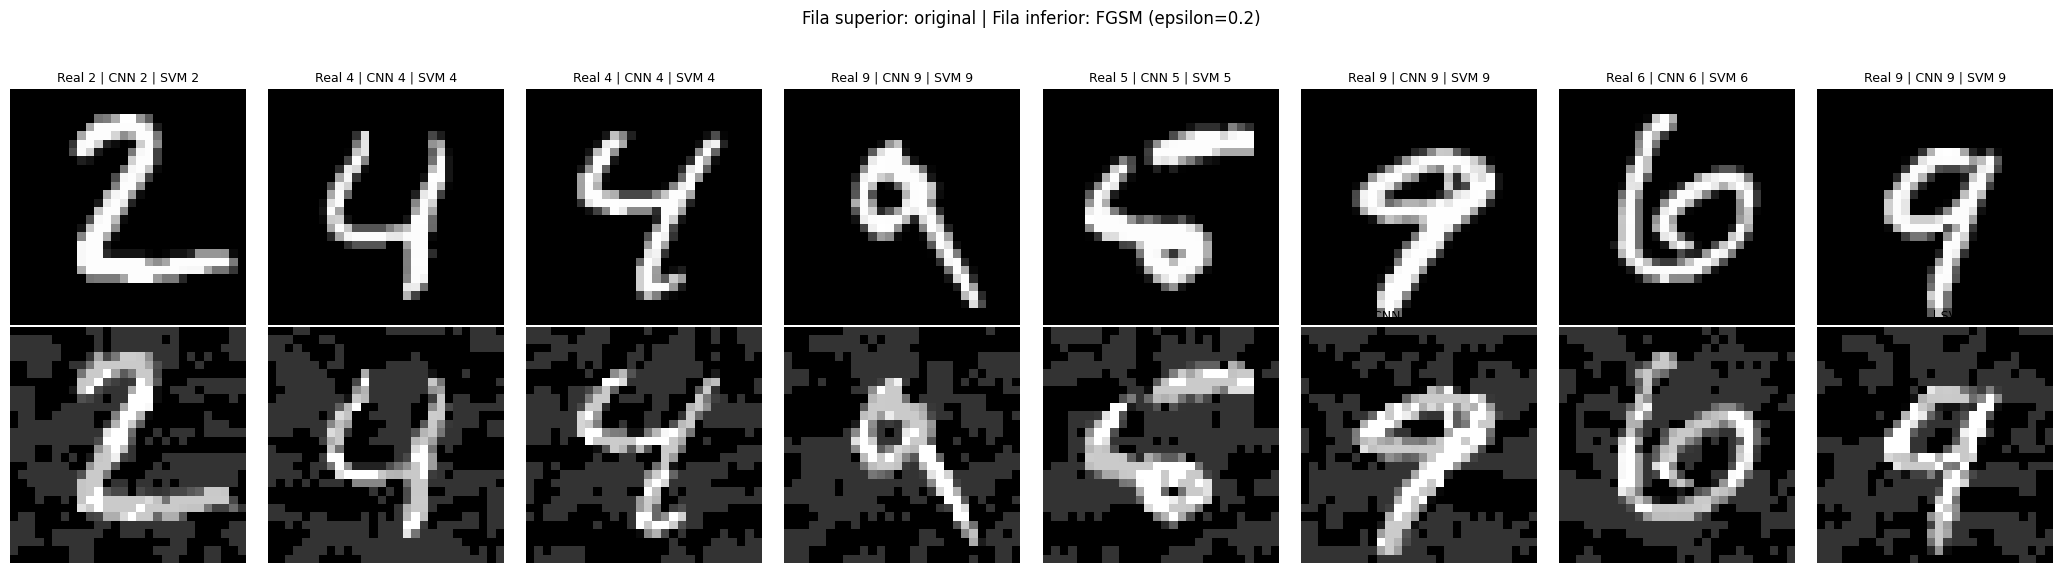

Imagen guardada: \\wsl.localhost\Ubuntu-24.04\home\laura\proyectos\practica1_parte2\resultados\originales_y_adversarias_eps_0_2.png


In [17]:
EPSILON = 0.20
NUM_MOSTRAR = 8

candidatos = []
for imagenes, etiquetas in cargador:
    x_adv = ataque_fgsm(cnn, imagenes, etiquetas, EPSILON)
    with torch.no_grad():
        p_cnn = cnn(imagenes).argmax(1).numpy()
        p_cnn_adv = cnn(x_adv).argmax(1).numpy()
    p_svm = svm.predict(imagenes.numpy().reshape(len(imagenes), 784))
    p_svm_adv = svm.predict(x_adv.numpy().reshape(len(x_adv), 784))
    for i in range(len(etiquetas)):
        real = int(etiquetas[i].item())
        if p_cnn[i] != real:
            continue  #imágenes correctamente clasificadas antes del ataque.
        cambio = int(p_cnn_adv[i] != real)
        candidatos.append((cambio, imagenes[i, 0].numpy(), x_adv[i, 0].numpy(),
                           real, int(p_cnn[i]), int(p_cnn_adv[i]),
                           int(p_svm[i]), int(p_svm_adv[i])))
    # modo completo se muestran ejemplos de los primeros lotes para evitar repetir todo el test
    if len(candidatos) >= 300:
        break

candidatos.sort(key=lambda registro: registro[0], reverse=True)
seleccion = candidatos[:NUM_MOSTRAR]
if not seleccion:
    raise RuntimeError("No se encontraron ejemplos inicialmente correctos para visualizar.")

fig, ejes = plt.subplots(2, len(seleccion), figsize=(2.6 * len(seleccion), 5.8), squeeze=False)
for j, (_, x, adv, real, p_cnn, p_cnn_adv, p_svm, p_svm_adv) in enumerate(seleccion):
    ejes[0, j].imshow(x, cmap="gray", vmin=0, vmax=1)
    ejes[1, j].imshow(adv, cmap="gray", vmin=0, vmax=1)
    ejes[0, j].set_title(f"Real {real} | CNN {p_cnn} | SVM {p_svm}", fontsize=9)
    ejes[1, j].set_title(f"CNN {p_cnn_adv} | SVM {p_svm_adv}", fontsize=9)
    for fila in range(2):
        ejes[fila, j].axis("off")
fig.suptitle(f"Fila superior: original | Fila inferior: FGSM (epsilon={EPSILON})", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.93])
archivo = CARPETA_SALIDAS / f"originales_y_adversarias_eps_{str(EPSILON).replace('.', '_')}.png"
fig.savefig(archivo, dpi=180)
plt.show()
print(f"Imagen guardada: {archivo}")


## 6. Apartado 5 (opcional): adversarias para todo train y test

Se fija EPS_OPT = 0.20 para toda la parte opcional. Con 0.20 la CNN ya cae claramente (la mayoría de los ataques acierta) y la SVM pierde bastante, pero el dígito sigue siendo reconocible a simple vista. Con 0,05–0,10 el efecto es pequeño y con >=0,30 la imagen se degrada tanto que casi no es un dígito.

Las 60.000 imágenes de train y las 10.000 de test se atacan contra la CNN original con la etiqueta verdadera, usando ataque_fgsm por lotes. Después se mide el error (100 − precisión) de cada modelo.

In [18]:
from IPython.display import Markdown
from adversarial import (cargar_mnist, generar_adversarias, predecir_cnn,
                         precision, SVMTorch, entrenar_cnn) 

X_tr, y_tr, X_te, y_te = cargar_mnist(CARPETA)
svm_t = SVMTorch(svm)
R = {}

In [19]:
# EPS_OPT: epsilon único de toda la parte opcional 
# Las adversarias se generan CONTRA LA CNN BASE con la etiqueta real; solo se calcula una vez.
EPS_OPT = 0.20
X_tr_adv = generar_adversarias(cnn, X_tr, y_tr, EPS_OPT)
X_te_adv = generar_adversarias(cnn, X_te, y_te, EPS_OPT)
assert (X_tr_adv - X_tr).abs().max() <= EPS_OPT + 1e-6 and (X_te_adv - X_te).abs().max() <= EPS_OPT + 1e-6

conjuntos = {"Train original (60.000)": (X_tr, y_tr), "Train adversario (60.000)": (X_tr_adv, y_tr),
             "Test original (10.000)": (X_te, y_te), "Test adversario (10.000)": (X_te_adv, y_te)}
filas = []
for nombre, (X, y) in conjuntos.items():
    filas.append({"Conjunto": nombre,
                  "Error CNN (%)": 100 - precision(predecir_cnn(cnn, X), y),
                  "Error SVM (%)": 100 - precision(svm_t.predict(X), y)})
ap5 = pd.DataFrame(filas)
ap5.to_csv(CARPETA_SALIDAS / "apartado5_errores.csv", index=False)
R["ap5"] = ap5
display(ap5.round(2))

,Conjunto,Error CNN (%),Error SVM (%)
0,Train original (60.000),1.04,0.01
1,Train adversario (60.000),76.94,46.47
2,Test original (10.000),1.39,1.63
3,Test adversario (10.000),76.09,47.43


## 7. Apartado 6 (opcional): entrenamiento adversario

- **CNN:** se reentrena desde cero con las 120.000 imágenes (60.000 originales + las 60.000 adversarias del apartado 5), con la misma configuración que el apartado 1 (Adam, lr 1e‑3, lote 128, 4 épocas, semilla 42).
- **SVM:** libsvm escala aproximadamente con $n^2$, tratamos de entrenar tambien con 60000 con los mismos C=10 y el mismo gamma numérico que la SVM base (si se dejara "scale" cambiaría al cambiar la varianza de los datos y estaríamos cambiando dos cosas a la vez).
- **Test conjunto (20.000):** las 10.000 de test originales + sus 10.000 adversarias (generadas contra la CNN original). Se compara el modelo base con el entrenado adversariamente.

Los modelos entrenados se guardan en resultados/ y se reutilizan si el notebook se ejecuta de nuevo.

In [20]:
# Entrenamiento adversario: se entrena con originales + adversarias. Los modelos se guardan en resultados/
ruta_cnn_adv = CARPETA_SALIDAS / "cnn_adversarial.pth"
ruta_svm_adv = CARPETA_SALIDAS / "svm_adversarial.joblib"

#CNN adversaria
if ruta_cnn_adv.is_file():
    cnn_adv = CNNMNIST(); cnn_adv.load_state_dict(torch.load(ruta_cnn_adv, weights_only=True)); cnn_adv.eval()
    print("CNN adversaria cargada de resultados/")
else:
    X_mix, y_mix = torch.cat([X_tr, X_tr_adv]), torch.cat([y_tr, y_tr])
    t0 = time.perf_counter()
    cnn_adv = entrenar_cnn(X_mix, y_mix, semilla=SEMILLA, X_val=X_te, y_val=y_te)
    torch.save(cnn_adv.state_dict(), ruta_cnn_adv)
    print(f"Entrenamiento CNN adversaria: {time.perf_counter() - t0:.0f} s")

#SVM adversaria
if ruta_svm_adv.is_file():
    svm_adv = joblib.load(ruta_svm_adv)
    print("SVM adversaria cargada de resultados/")
else:
    from sklearn.svm import SVC
    idx12 = np.random.default_rng(SEMILLA).choice(len(X_tr), 60000, replace=False) 
    Xs = torch.cat([X_tr[idx12], X_tr_adv[idx12]]).numpy().reshape(-1, 784)
    ys = torch.cat([y_tr[idx12], y_tr[idx12]]).numpy()
    t0 = time.perf_counter()
    svm_adv = SVC(kernel="rbf", C=10.0, gamma=float(svm._gamma), cache_size=1000).fit(Xs, ys)
    joblib.dump(svm_adv, ruta_svm_adv, compress=3)
    print(f"Entrenamiento SVM adversaria: {time.perf_counter() - t0:.0f} s")
svm_adv_t = SVMTorch(svm_adv)
chk = (svm_adv.predict(X_te[:1000].numpy().reshape(-1, 784)) == svm_adv_t.predict(X_te[:1000])).mean() * 100
print(f"Parámetros CNN: {sum(p.numel() for p in cnn_adv.parameters()):,} | vectores de soporte SVM adversaria: {len(svm_adv.support_):,} "
      f"(base: {len(svm.support_):,}) | equivalencia SVMTorch: {chk:.2f}%")

Época 1/4 | pérdida train 0.2601 | acierto test limpio 96.83%
Época 2/4 | pérdida train 0.0512 | acierto test limpio 98.30%
Época 3/4 | pérdida train 0.0328 | acierto test limpio 98.67%
Época 4/4 | pérdida train 0.0241 | acierto test limpio 98.70%
Entrenamiento CNN adversaria: 87 s
Entrenamiento SVM adversaria: 1165 s
Parámetros CNN: 105,866 | vectores de soporte SVM adversaria: 19,950 (base: 11,697) | equivalencia SVMTorch: 100.00%


,Modelo,Error test original (%),Error test adversario (%),Error test conjunto 20.000 (%)
0,CNN base,1.39,76.09,38.74
1,CNN adversaria,1.30,0.22,0.76
2,SVM base,1.63,47.43,24.53
3,SVM adversaria,1.55,0.45,1.00


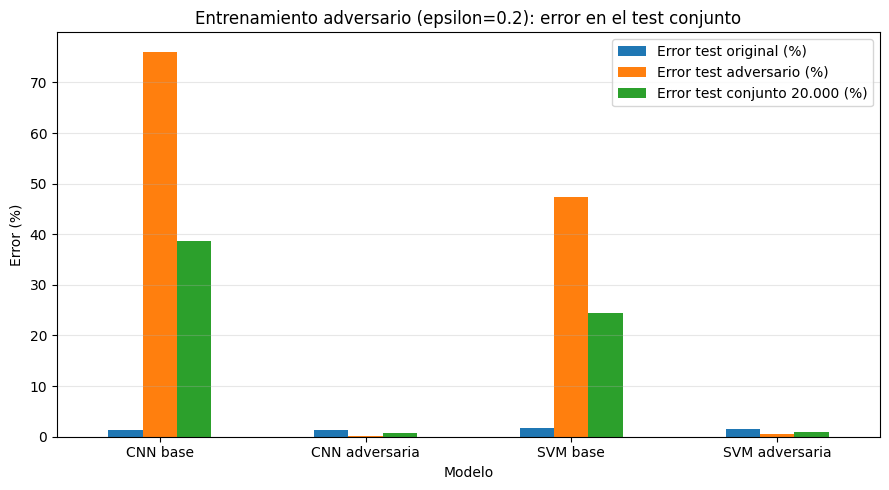

In [21]:
# Test conjunto: 10.000 originales + sus 10.000 adversarias (generadas contra la CNN BASE) = 20.000 imágenes
X_joint = torch.cat([X_te, X_te_adv]); y_joint = torch.cat([y_te, y_te])
modelos = {"CNN base": lambda X: predecir_cnn(cnn, X), "CNN adversaria": lambda X: predecir_cnn(cnn_adv, X),
           "SVM base": svm_t.predict, "SVM adversaria": svm_adv_t.predict}
filas = []
for nombre, pred in modelos.items():
    filas.append({"Modelo": nombre,
                  "Error test original (%)": 100 - precision(pred(X_te), y_te),
                  "Error test adversario (%)": 100 - precision(pred(X_te_adv), y_te),
                  "Error test conjunto 20.000 (%)": 100 - precision(pred(X_joint), y_joint)})
ap6 = pd.DataFrame(filas)
ap6.to_csv(CARPETA_SALIDAS / "apartado6_errores.csv", index=False)
R["ap6"] = ap6
display(ap6.round(2))

ax = ap6.set_index("Modelo").plot.bar(figsize=(9, 5), rot=0)
ax.set(ylabel="Error (%)", title=f"Entrenamiento adversario (epsilon={EPS_OPT}): error en el test conjunto")
ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(CARPETA_SALIDAS / "apartado6_errores.png", dpi=180); plt.show()

## 8. Apartado 7 (opcional): imágenes «doblemente adversarias»

Se ataca cada una de las 60.000 imágenes adversarias de train contra el modelo entrenado adversariamente (con la etiqueta real), con el mismo epsilon. La distancia total respecto a la imagen original puede llegar a 2·epsilon, y por eso se mide el máximo real.

Se evalúa el rendimiento del modelo entrenado adversariamente sobre ellas, y se comparan varios casos para entender el resultado:

- FGSM contra la CNN adversaria y contra la SVM adversaria
- Los modelos base sobre las mismas imágenes, como referencia.
- Un único paso de FGSM contra la CNN adversaria partiendo de la original (distancia <= epsilon), para separar el efecto de atacar de nuevo del efecto de tener un epsilon mayor.
- Lo mismo con las 10.000 imágenes de test, porque la CNN adversaria sí vio las de train durante el entrenamiento.

In [22]:
# Apartado 7: se vuelve a aplicar FGSM sobre las adversarias, ahora contra el modelo ADVERSARIO.
# Cada imagen puede estar hasta 2·epsilon de la original (se comprueba con la distancia L-inf máxima).
def evaluar_doble(nombre, X_ori, X_adv1, y):
    """Genera doblemente adversarias contra cada modelo adversario y evalúa a los cuatro modelos."""
    dd_cnn = generar_adversarias(cnn_adv, X_adv1, y, EPS_OPT)        # contra la CNN adversaria
    dd_svm = generar_adversarias(svm_adv_t, X_adv1, y, EPS_OPT)      # contra la SVM adversaria
    dist = max((dd_cnn - X_ori).abs().max().item(), (dd_svm - X_ori).abs().max().item())
    assert dist <= 2 * EPS_OPT + 1e-5
    filas = []
    for etiqueta, X in [("Adversarias (1 ataque, contra CNN base)", X_adv1),
                        ("Doblemente adversarias (contra CNN adversaria)", dd_cnn),
                        ("Doblemente adversarias (contra SVM adversaria)", dd_svm)]:
        filas.append({"Conjunto": f"{nombre}: {etiqueta}",
                      "CNN base": precision(predecir_cnn(cnn, X), y),
                      "CNN adversaria": precision(predecir_cnn(cnn_adv, X), y),
                      "SVM base": precision(svm_t.predict(X), y),
                      "SVM adversaria": precision(svm_adv_t.predict(X), y)})
    return pd.DataFrame(filas), dist, dd_cnn

ap7_tr, dist_tr, X_dd_tr = evaluar_doble("Train", X_tr, X_tr_adv, y_tr)
ap7_te, dist_te, X_dd_te = evaluar_doble("Test", X_te, X_te_adv, y_te)
ap7 = pd.concat([ap7_tr, ap7_te], ignore_index=True)
ap7.to_csv(CARPETA_SALIDAS / "apartado7_precision.csv", index=False)
R["ap7"], R["dist"] = ap7, (dist_tr, dist_te)
print(f"Distancia L-inf máxima respecto a la original: train {dist_tr:.3f} | test {dist_te:.3f} (cota teórica 2·eps = {2 * EPS_OPT:.2f})")
display(ap7.round(2))

# Casos de comparación sobre test
x_directa = generar_adversarias(cnn_adv, X_te, y_te, EPS_OPT)               # un paso, desde la original
x_directa2 = generar_adversarias(cnn_adv, X_te, y_te, 2 * EPS_OPT)          # un paso con 2·eps
comp = pd.DataFrame([
    {"Ataque contra la CNN adversaria (test)": f"FGSM desde la original, eps={EPS_OPT}", "Precisión CNN adversaria (%)": precision(predecir_cnn(cnn_adv, x_directa), y_te)},
    {"Ataque contra la CNN adversaria (test)": f"FGSM doble (adversaria→adversaria), eps={EPS_OPT} dos veces", "Precisión CNN adversaria (%)": precision(predecir_cnn(cnn_adv, X_dd_te), y_te)},
    {"Ataque contra la CNN adversaria (test)": f"FGSM desde la original, eps={2 * EPS_OPT}", "Precisión CNN adversaria (%)": precision(predecir_cnn(cnn_adv, x_directa2), y_te)},
])
comp.to_csv(CARPETA_SALIDAS / "apartado7_comparacion_cnn_adv.csv", index=False)
R["comp"] = comp
display(comp.round(2))

Distancia L-inf máxima respecto a la original: train 0.400 | test 0.400 (cota teórica 2·eps = 0.40)


,Conjunto,CNN base,CNN adversaria,SVM base,SVM adversaria
0,"Train: Adversarias (1 ataque, contra CNN base)",23.06,99.91,53.53,100.00
1,Train: Doblemente adversarias (contra CNN adve...,16.34,0.19,29.59,10.88
2,Train: Doblemente adversarias (contra SVM adve...,17.03,0.04,1.53,0.01
3,"Test: Adversarias (1 ataque, contra CNN base)",23.91,99.78,52.57,99.55
4,Test: Doblemente adversarias (contra CNN adver...,17.07,0.23,30.34,11.94
5,Test: Doblemente adversarias (contra SVM adver...,17.35,0.05,1.63,0.00


,Ataque contra la CNN adversaria (test),Precisión CNN adversaria (%)
0,"FGSM desde la original, eps=0.2",1.34
1,"FGSM doble (adversaria→adversaria), eps=0.2 do...",0.23
2,"FGSM desde la original, eps=0.4",0.06


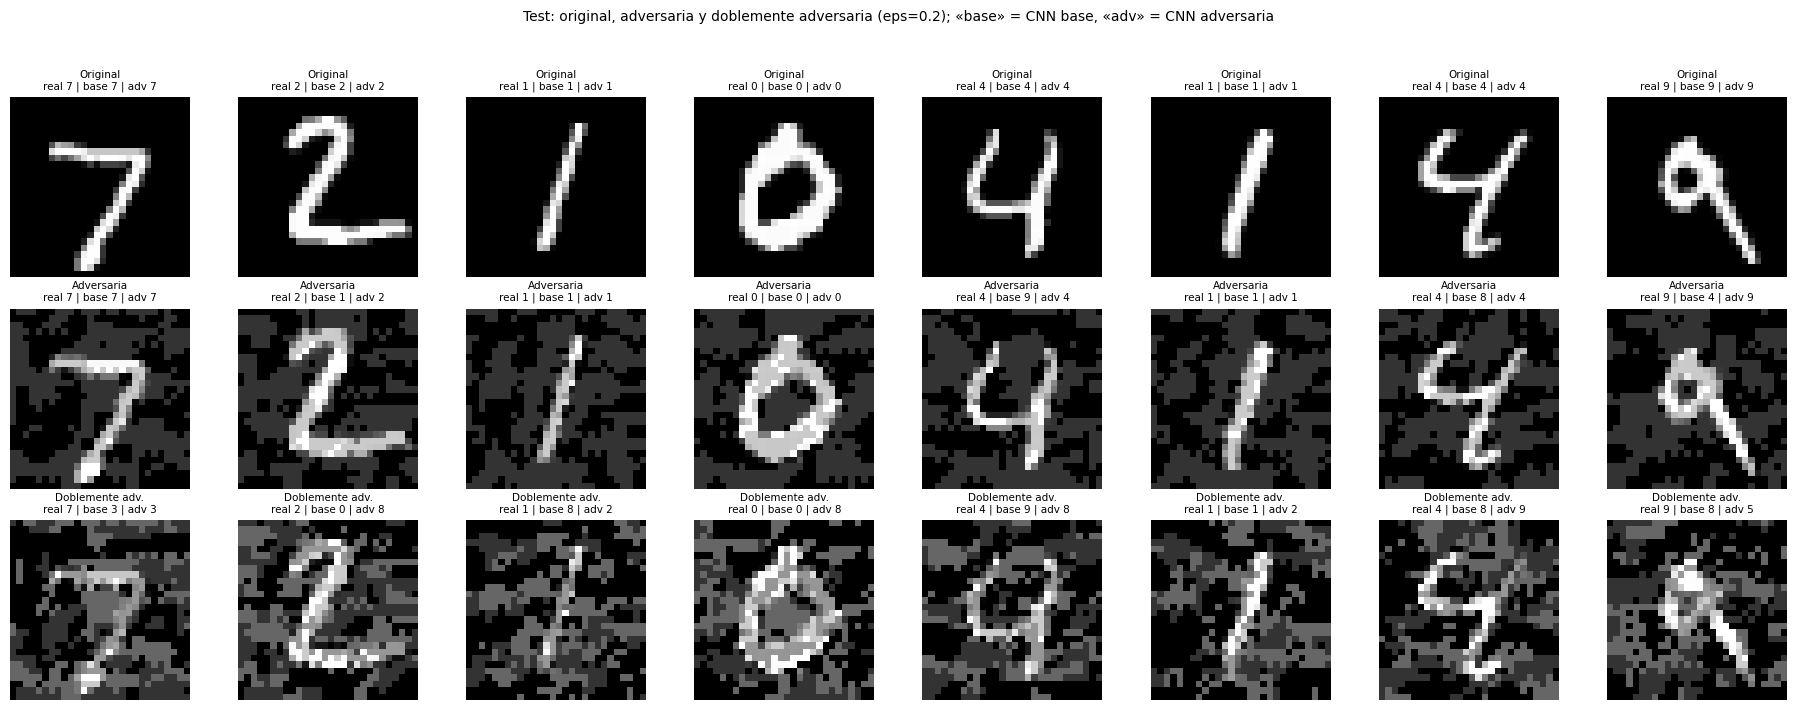

In [23]:
# Visualización: original -> adversaria (contra CNN base) -> doblemente adversaria (contra CNN adversaria)
sel = list(range(8))
fig, ejes = plt.subplots(3, len(sel), figsize=(2.3 * len(sel), 7.2))
filas_img = [("Original", X_te), ("Adversaria", X_te_adv), ("Doblemente adv.", X_dd_te)]
for f, (titulo, X) in enumerate(filas_img):
    pcb = predecir_cnn(cnn, X[sel]); pca = predecir_cnn(cnn_adv, X[sel])
    for j, k in enumerate(sel):
        ejes[f, j].imshow(X[k, 0], cmap="gray", vmin=0, vmax=1)
        ejes[f, j].set_title(f"{titulo}\nreal {int(y_te[k])} | base {pcb[j]} | adv {pca[j]}", fontsize=7.5)
        ejes[f, j].axis("off")
fig.suptitle(f"Test: original, adversaria y doblemente adversaria (eps={EPS_OPT}); «base» = CNN base, «adv» = CNN adversaria", fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(CARPETA_SALIDAS / "apartado7_doblemente_adversarias.png", dpi=180)
plt.show()

## 9. Conclusiones

### Obligatorio (apartados 1–4)

- **Apartado 1.** La CNN (2 capas convolucionales + 2 lineales) tiene 105,866 parámetros y alcanza 98.61 % en test (> 95 %).
- **Apartado 2.** La SVM RBF (C=10, gamma="scale") entrenada con 60000 imágenes alcanza 98.37 % en test, con 11,697 vectores de soporte.
- **Apartados 3–4.** Con epsilon=0.2 la CNN baja a 23.91 % y FGSM acierta a engañarla en el 75.8 % de las imágenes que clasificaba bien. La SVM, que no fue atacada directamente, baja a 52.57 % (46.6 % de las que acertaba pasan a fallar): hay transferencia, aunque menor.
- **Más epsilon = más daño**, y la caída no es lineal: con epsilon<=0.05 el efecto es pequeño (CNN 94.5 %), el hundimiento ocurre entre 0.10 (80.3 %) y 0.20 (23.9 %), y con 0.30 la CNN casi nunca acierta (3.0 %).
- **Elección de epsilon.** Se usa 0.2 porque es donde el ataque ya es claramente eficaz y la imagen sigue siendo legible para una persona.

### Opcionales (apartados 5–7)

- **Apartado 5 (todo train y test, epsilon=0.2).** Error de la CNN: 1.04 % -> 76.94 % en train y 1.39 % -> 76.09 % en test. Error de la SVM: 0.01 % -> 46.47 % en train y 1.63 % -> 47.43 % en test. Train y test se comportan igual, así que el ataque no depende de que el modelo haya visto o no la imagen.
- **Apartado 6 (entrenamiento adversario, test conjunto de 20.000).** Error de la CNN: 38.74 % -> 0.76 %; de la SVM: 24.53 % -> 1.00 %. El error sobre imágenes limpias apenas cambia (CNN 1.30 %, SVM 1.55 %), es decir, la robustez gratis respecto a estas adversarias no cuesta precisión limpia.
- **Apartado 7 (doblemente adversarias).** Sobre las 60.000 doblemente adversarias generadas contra la CNN adversaria, esta acierta solo el 0.19 % (en test: 0.23 %), cuando sobre las adversarias de un solo ataque acertaba 99.78 %. La SVM adversaria acierta 10.9 % sobre esas mismas imágenes (transferencia), y 0.00 % cuando el segundo ataque va dirigido contra ella.

### Idea clave

El entrenamiento adversario del enunciado (aumentar con adversarias generadas una sola vez contra el modelo base) hace que los modelos resistan ese tipo concreto de imágenes*(error en el test conjunto muy bajo), pero no los hace robustos: basta volver a calcular el ataque contra el modelo ya reentrenado para que caiga de nuevo a = 0 % (apartado 7). La CNN adversaria cae a 1.34 % con un único FGSM desde la original. Una defensa real exigiría regenerar las adversarias contra el modelo actual en cada paso del entrenamiento (entrenamiento adversario iterativo), con su coste computacional.